# 🚀 Модуль 13. Урок 4. Сквозной кейс: Data Storytelling и структура «Что? Ну и что? Что делать?»

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_13_soft_skills_storytelling/lesson_04_data_storytelling_case_study.ipynb)

## 📌 Бизнес-контекст и методология
Руководители C-Level не хотят видеть сырой SQL или 20 разрозненных графиков без выводов. 
Эталонная подача аналитики строится по трехактной структуре McKinsey / Google:
1. **Что произошло? (Fact):** Внезапное падение конверсии на 14% в июне.
2. **Ну и что? (Impact & Root Cause):** Потери $120,000/мес; баг затронул только пользователей Safari на iOS 18.
3. **Что делать? (Recommendation):** Срочный хотфикс платежного SDK + ретроспектива QA.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

ab_csv = ensure_dataset("ab_test_checkout.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Смоделируем временной ряд инцидента с конверсией и разложим его по браузерным сегментам.

In [2]:
np.random.seed(42)
dates = pd.date_range('2026-06-01', periods=30, freq='D')

# Нормальная конверсия 8.5%
chrome_cr = 0.085 + np.random.normal(0, 0.003, 30)
# Safari падает после релиза 12 июня
safari_cr = 0.085 + np.random.normal(0, 0.003, 30)
safari_cr[11:] -= 0.035  # обвал до 5.0%

total_cr = 0.6 * chrome_cr + 0.4 * safari_cr
print("Средняя конверсия до 12 июня:   {:.2%}".format(np.mean(total_cr[:11])))
print("Средняя конверсия после 12 июня: {:.2%}".format(np.mean(total_cr[11:])))

Средняя конверсия до 12 июня:   8.54%
Средняя конверсия после 12 июня: 7.00%


### 📊 Визуализация: Аннотированная нарративная диаграмма инцидента
График ниже оформлен в стиле The Economist и Financial Times: четкая аннотация момента релиза, подсветка корневой причины и стрелка решения.

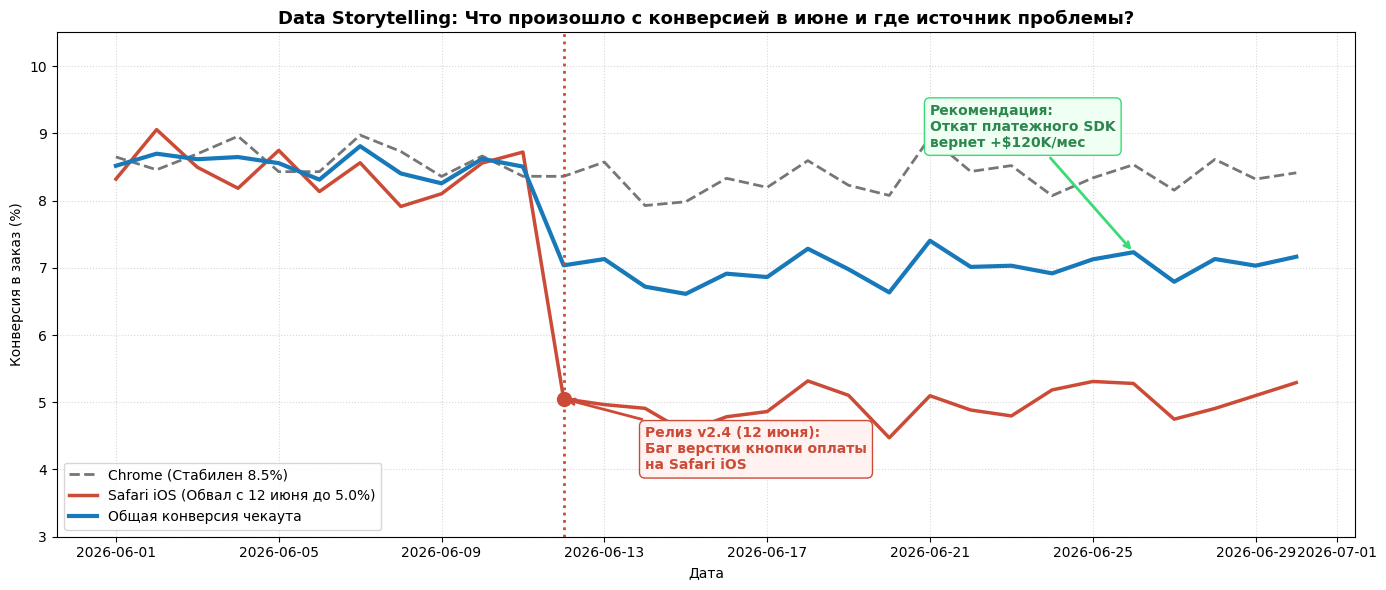

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(dates, chrome_cr * 100, color='#767676', linewidth=2, linestyle='--', label='Chrome (Стабилен 8.5%)')
ax.plot(dates, safari_cr * 100, color='#cc4b37', linewidth=2.5, label='Safari iOS (Обвал с 12 июня до 5.0%)')
ax.plot(dates, total_cr * 100, color='#1779ba', linewidth=3, label='Общая конверсия чекаута')

# Аннотация инцидента
release_date = dates[11]
ax.axvline(release_date, color='#cc4b37', linestyle=':', linewidth=2)
ax.scatter(release_date, safari_cr[11] * 100, color='#cc4b37', s=100, zorder=5)

ax.annotate('Релиз v2.4 (12 июня):\nБаг верстки кнопки оплаты\nна Safari iOS',
            xy=(release_date, safari_cr[11] * 100),
            xytext=(dates[13], 4.0),
            arrowprops=dict(arrowstyle="->", color='#cc4b37', lw=2),
            fontweight='bold', color='#cc4b37', bbox=dict(boxstyle="round,pad=0.4", fc="#fff2f0", ec="#cc4b37"))

# Аннотация хотфикса
ax.annotate('Рекомендация:\nОткат платежного SDK\nвернет +$120K/мес',
            xy=(dates[25], total_cr[25] * 100),
            xytext=(dates[20], 8.8),
            arrowprops=dict(arrowstyle="->", color='#3adb76', lw=2),
            fontweight='bold', color='#2d864e', bbox=dict(boxstyle="round,pad=0.4", fc="#f0fff4", ec="#3adb76"))

ax.set_title('Data Storytelling: Что произошло с конверсией в июне и где источник проблемы?', fontsize=13, fontweight='bold')
ax.set_xlabel('Дата')
ax.set_ylabel('Конверсия в заказ (%)')
ax.set_ylim(3.0, 10.5)
ax.legend(loc='lower left')
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет финансовых потерь от инцидента
Если в день на чекаут заходят 10,000 пользователей, средний чек $45, а падение конверсии составило 1.4 п.п. (0.014), сколько компания теряет за 18 дней бага?

In [4]:
### ВАШ КОД ЗДЕСЬ
daily_visitors = 10000
aov = 45.0
cr_drop = 0.014
days_incident = 18

lost_orders_daily = daily_visitors * cr_drop
total_revenue_loss = lost_orders_daily * aov * days_incident

print(f"Потеряно заказов в день: {int(lost_orders_daily)}")
print(f"Суммарные потери выручки: ${total_revenue_loss:,.0f}")

assert total_revenue_loss == 113400.0, "Потери: 10000 * 0.014 * 45 * 18 = 113,400$"
print("✅ Тест успешно пройден!")

Потеряно заказов в день: 140
Суммарные потери выручки: $113,400
✅ Тест успешно пройден!


### 💼 Золотое правило C-Level презентации:
Всегда завершайте аналитический отчет слайдом с конкретным планом действий (Action Items), ответственными лицами и ожидаемым финансовым эффектом в долларах.